# Topology-Aware Model Performance Analysis

This notebook relates model performance on the 360 PSPLIB evaluation projects to project topological descriptors from `PSPLIB_sample/psplib_sample_metadata.csv`.

## Goal

The main evaluation notebook compares the six selected model hyperparameterizations at aggregate level. Here we ask whether model performance changes systematically with project topology.

The topological descriptors considered are those proposed by Vanhoucke (2008):

- `#Act`: Number of activities
- `CNC`: Coefficient of Network Complexity
- `OS`: Order Strength
- `SP`: Serial-Parallel Network Indicator
- `AD`: Activity Distribution Indicator
- `LA`: Length Arcs Indicator
- `I5`: I5 Indicator
- `TF`: Total Float Indicator

`SP` receives special attention because it captures the degree of seriality versus parallelism in the project network, which directly affects how much of the network behaves as critical or near-critical.

In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as ss
import scikit_posthocs as sp

In [6]:
sns.set_theme(style="darkgrid")
sns.set_palette("colorblind")
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 6)

In [7]:
results_dir = Path("./model_evaluation/results")
metadata_path = Path("./PSPLIB_sample/psplib_sample_metadata.csv")
work_dir = Path("./model_evaluation/analysis")
work_dir.mkdir(parents=True, exist_ok=True)

model_order = ["ebm", "rf", "xgb", "sv", "en", "fastai"]
expected_lhs = {
    "ebm": 24,
    "rf": 14,
    "xgb": 39,
    "sv": 0,
    "en": 36,
    "fastai": 41,
}
model_labels = {model: f"{model}-{lhs}" for model, lhs in expected_lhs.items()}
model_label_order = [model_labels[model] for model in model_order]
model_palette = dict(zip(model_label_order, sns.color_palette("colorblind", n_colors=len(model_label_order))))

topology_cols = ["#Act", "CNC", "OS", "SP", "AD", "LA", "I5", "TF"]

## Load Evaluation Results

Only comparison-level fields are loaded from the per-project result files. Model-specific hyperparameter columns are deliberately discarded.

In [8]:
def load_evaluation_results(
    results_dir: Path,
    expected_lhs: dict[str, int],
) -> pd.DataFrame:
    """Load evaluation CSV files and keep the selected LHS configuration."""

    files = sorted(results_dir.glob("model_evaluation_*_lhs_*_subset_*_project_*.csv"))
    cols = ["project", "subset", "model", "lhs", "RelMSE", "time"]

    if not files:
        raise FileNotFoundError(f"No evaluation files found in {results_dir}")

    results = pd.concat(
        [pd.read_csv(file, usecols=cols) for file in files],
        ignore_index=True,
    )

    results = results.assign(
        project=lambda df: df["project"].astype(str),
        subset=lambda df: df["subset"].astype(str).str.upper(),
        model=lambda df: df["model"].astype(str),
        lhs=lambda df: df["lhs"].astype(int),
        RelMSE=lambda df: pd.to_numeric(df["RelMSE"]),
        time=lambda df: pd.to_numeric(df["time"]),
    )

    results["model_label"] = (
        results["model"] + "-" + results["model"].map(expected_lhs).astype(str)
    )

    selected = results["lhs"].eq(results["model"].map(expected_lhs))
    if not selected.all():
        display(results.loc[~selected, cols].head())
        raise ValueError("Some rows do not match the selected LHS configuration")

    return results

results = load_evaluation_results(results_dir, expected_lhs)
print(f"Rows: {len(results)}")
print(f"Projects: {results['project'].nunique()}")
print(f"Models: {results['model_label'].nunique()}")
display(results.head())

Rows: 2160
Projects: 360
Models: 6


,project,subset,model,lhs,RelMSE,time,model_label
0,j12010_6,J120,ebm,24,0.000169,3670.0,ebm-24
1,j12010_7,J120,ebm,24,0.006494,1331.0,ebm-24
2,j12011_2,J120,ebm,24,0.000336,3826.0,ebm-24
3,j12012_3,J120,ebm,24,0.010618,668.0,ebm-24
4,j12012_4,J120,ebm,24,0.000228,2595.0,ebm-24


## Load Topological Metadata

The metadata file contains 400 sampled projects: 40 were used during model selection and 360 are used here for model evaluation. The join is validated by project identifier rather than relying only on the flags.

In [9]:
def load_topology_metadata(
    metadata_path: Path,
    topology_cols: list[str],
    evaluation_projects: pd.Index,
) -> pd.DataFrame:
    """Load topology metadata for the evaluated projects."""

    cols = ["SubSet", "FileName", "sample", "model_selection", *topology_cols]

    metadata = pd.read_csv(metadata_path, usecols=cols)

    metadata = metadata.rename(columns={"SubSet": "metadata_subset"})
    metadata["metadata_subset"] = metadata["metadata_subset"].astype(str).str.upper()
    metadata["project"] = metadata["FileName"].astype(str).str.replace(".sm", "", regex=False)

    metadata[topology_cols] = metadata[topology_cols].apply(pd.to_numeric)

    return metadata.loc[metadata["project"].isin(evaluation_projects)].copy()

topology = load_topology_metadata(metadata_path, topology_cols, results["project"].unique())
print(f"Topology rows matched to evaluation projects: {len(topology)}")
display(topology[["project", "metadata_subset", "sample", "model_selection", *topology_cols]].head())

Topology rows matched to evaluation projects: 360


,project,metadata_subset,sample,model_selection,#Act,CNC,OS,SP,AD,LA,I5,TF
0,j1201_3,J120,True,False,120,1.48,0.18,0.11,0.38,0.01,0.76,0.30
2,j1201_9,J120,True,False,120,1.48,0.18,0.12,0.38,0.00,0.72,0.28
3,j1202_2,J120,True,False,120,1.48,0.17,0.10,0.40,0.01,0.80,0.26
4,j1203_1,J120,True,False,120,1.48,0.18,0.11,0.38,0.01,0.79,0.23
5,j1204_7,J120,True,False,120,1.48,0.19,0.12,0.37,0.01,0.77,0.29


In [10]:
analysis_data = results.merge(
    topology[["project", "metadata_subset", *topology_cols]],
    on="project",
    how="left",
)

relmse_matrix = (
    analysis_data
    .pivot(index="project", columns="model_label", values="RelMSE")
    .reindex(columns=model_label_order)
)

time_matrix = (
    analysis_data
    .pivot(index="project", columns="model_label", values="time")
    .reindex(columns=model_label_order)
)

rank_matrix = relmse_matrix.rank(axis=1, ascending=True, method="average")
time_rank_matrix = time_matrix.rank(axis=1, ascending=True, method="average")

best_model = relmse_matrix.idxmin(axis=1).rename("best_model")

analysis_data = analysis_data.merge(
    rank_matrix
    .rename_axis("project")
    .reset_index()
    .melt(id_vars="project", var_name="model_label", value_name="RelMSE_rank"),
    on=["project", "model_label"],
    how="left",
)

analysis_data = analysis_data.merge(
    time_rank_matrix
    .rename_axis("project")
    .reset_index()
    .melt(id_vars="project", var_name="model_label", value_name="time_rank"),
    on=["project", "model_label"],
    how="left",
)

analysis_data = analysis_data.merge(
    best_model.reset_index(),
    on="project",
    how="left",
)

analysis_data["is_best_model"] = analysis_data["model_label"].eq(analysis_data["best_model"])
analysis_data["log_RelMSE"] = np.log1p(analysis_data["RelMSE"])

project_topology = (
    topology
    .set_index("project")
    .loc[relmse_matrix.index, ["metadata_subset", *topology_cols]]
)

print(f"Missing RelMSE values: {int(relmse_matrix.isna().sum().sum())}")
print(f"Missing time values: {int(time_matrix.isna().sum().sum())}")

display(analysis_data.head())

Missing RelMSE values: 0
Missing time values: 0


,project,subset,model,lhs,RelMSE,time,model_label,metadata_subset,#Act,CNC,OS,SP,AD,LA,I5,TF,RelMSE_rank,time_rank,best_model,is_best_model,log_RelMSE
0,j12010_6,J120,ebm,24,0.000169,3670.0,ebm-24,J120,120,1.48,0.19,0.12,0.31,0.00,0.73,0.28,2.0,6.0,en-36,False,0.000169
1,j12010_7,J120,ebm,24,0.006494,1331.0,ebm-24,J120,120,1.48,0.17,0.09,0.31,0.01,0.76,0.20,2.0,6.0,en-36,False,0.006473
2,j12011_2,J120,ebm,24,0.000336,3826.0,ebm-24,J120,120,1.48,0.16,0.11,0.43,0.00,0.77,0.33,2.0,6.0,en-36,False,0.000336
3,j12012_3,J120,ebm,24,0.010618,668.0,ebm-24,J120,120,1.48,0.18,0.12,0.44,0.01,0.80,0.26,3.0,5.0,fastai-41,False,0.010562
4,j12012_4,J120,ebm,24,0.000228,2595.0,ebm-24,J120,120,1.48,0.18,0.14,0.46,0.01,0.78,0.42,2.0,6.0,en-36,False,0.000228


## Topology Overview

Before linking topology to model behavior, inspect the distributions and correlations among the eight topological descriptors. Strong correlations between topology variables should be considered when interpreting model-specific relationships.

#Act                   CNC                         OS  \
                  mean median  std      mean median       std      mean   
metadata_subset                                                           
J120             120.0  120.0  0.0  1.779667   1.78  0.239726  0.276444   
J30               30.0   30.0  0.0  1.748222   1.73  0.274753  0.451111   
J60               60.0   60.0  0.0  1.770000   1.77  0.264991  0.361556   
J90               90.0   90.0  0.0  1.797222   1.78  0.260242  0.313333   

                                        SP                         AD         \
                median       std      mean median       std      mean median   
metadata_subset                                                                
J120              0.27  0.080061  0.126444   0.13  0.015014  0.329778   0.33   
J30               0.45  0.101222  0.256667   0.24  0.030722  0.290778   0.27   
J60               0.36  0.087409  0.191778   0.19  0.022163  0.312556   0.31   
J90               0.32  0.084268  0.154222   0.15  0.017987  0.319778   0.32   

                                 LA                         I5         \
                      std      mean median       std      mean median   
metadata_subset                                                         
J120             0.064997  0.011111   0.01  0.006261  0.788111   0.79   
J30              0.081257  0.069444   0.07  0.040706  0.765333   0.78   
J60              0.068754  0.025111   0.02  0.015305  0.768556   0.77   
J90              0.072126  0.014889   0.01  0.008643  0.775556   0.78   

                                 TF                   
                      std      mean median       std  
metadata_subset                                       
J120             0.024718  0.242333  0.245  0.061845  
J30              0.053300  0.220667  0.210  0.085286  
J60              0.035807  0.239778  0.240  0.072530  
J90              0.033423  0.243333  0.240  0.071846

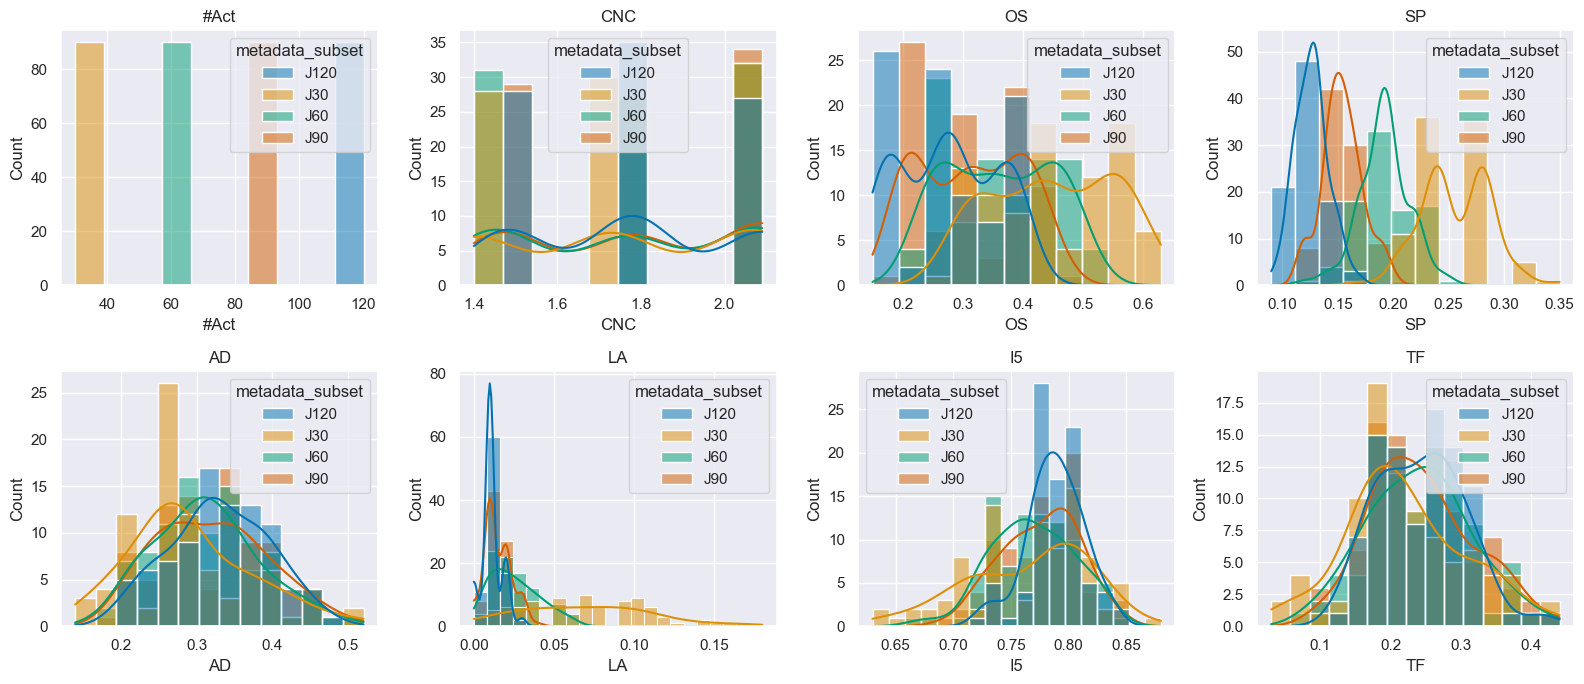

In [11]:
display(project_topology.groupby("metadata_subset")[topology_cols].agg(["mean", "median", "std"]))

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), topology_cols):
    sns.histplot(data=project_topology.reset_index(), x=col, hue="metadata_subset", kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

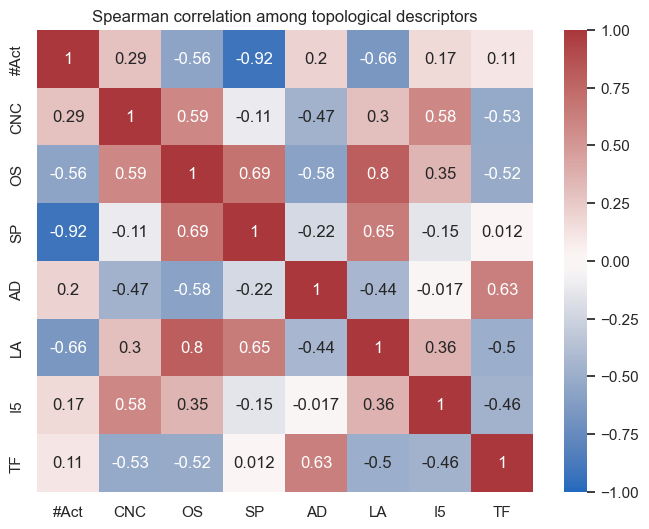

,#Act,CNC,OS,SP,AD,LA,I5,TF
#Act,1.000000,0.285941,-0.563597,-0.915493,0.204716,-0.662207,0.171090,0.111217
CNC,0.285941,1.000000,0.585261,-0.111740,-0.465930,0.303047,0.582892,-0.527600
OS,-0.563597,0.585261,1.000000,0.687764,-0.578762,0.797911,0.346614,-0.523311
SP,-0.915493,-0.111740,0.687764,1.000000,-0.215073,0.645142,-0.145700,0.012409
AD,0.204716,-0.465930,-0.578762,-0.215073,1.000000,-0.435276,-0.017034,0.629786
LA,-0.662207,0.303047,0.797911,0.645142,-0.435276,1.000000,0.360504,-0.499264
I5,0.171090,0.582892,0.346614,-0.145700,-0.017034,0.360504,1.000000,-0.462580
TF,0.111217,-0.527600,-0.523311,0.012409,0.629786,-0.499264,-0.462580,1.000000


In [12]:
topology_corr = project_topology[topology_cols].corr(method="spearman")

plt.figure(figsize=(8, 6))
sns.heatmap(topology_corr, annot=True, cmap="vlag", center=0, vmin=-1, vmax=1)
plt.title("Spearman correlation among topological descriptors")
plt.show()

topology_corr

## Model Performance Across SP

`SP` is the primary topology variable in this analysis. The following plots relate `SP` to model error and model rank. Rank is often easier to interpret than raw `RelMSE` because it compares models within the same project instance.

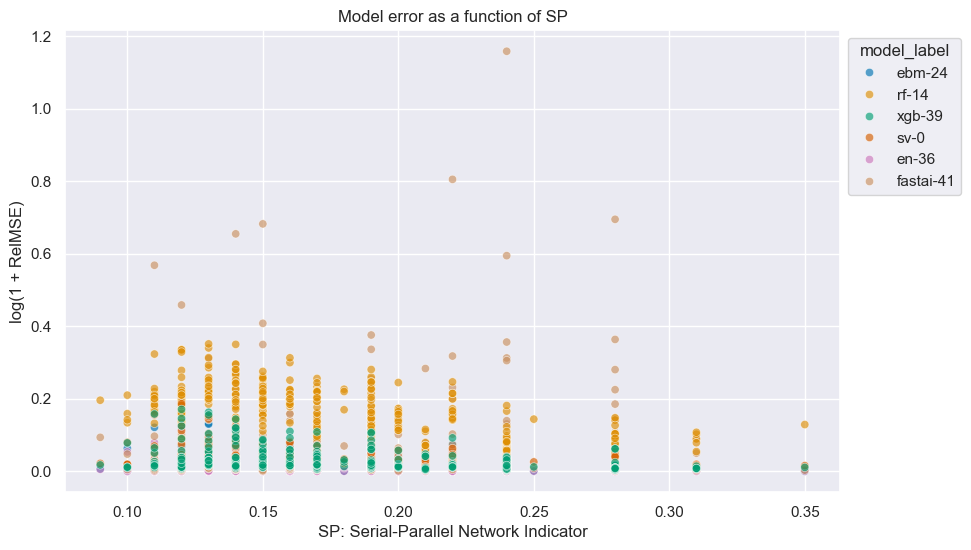

In [13]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=analysis_data, x="SP", y="log_RelMSE", hue="model_label", hue_order=model_label_order, palette=model_palette, alpha=0.65)
sns.move_legend(plt.gca(), "upper left", bbox_to_anchor=(1, 1))
plt.title("Model error as a function of SP")
plt.xlabel("SP: Serial-Parallel Network Indicator")
plt.ylabel("log(1 + RelMSE)")
plt.show()

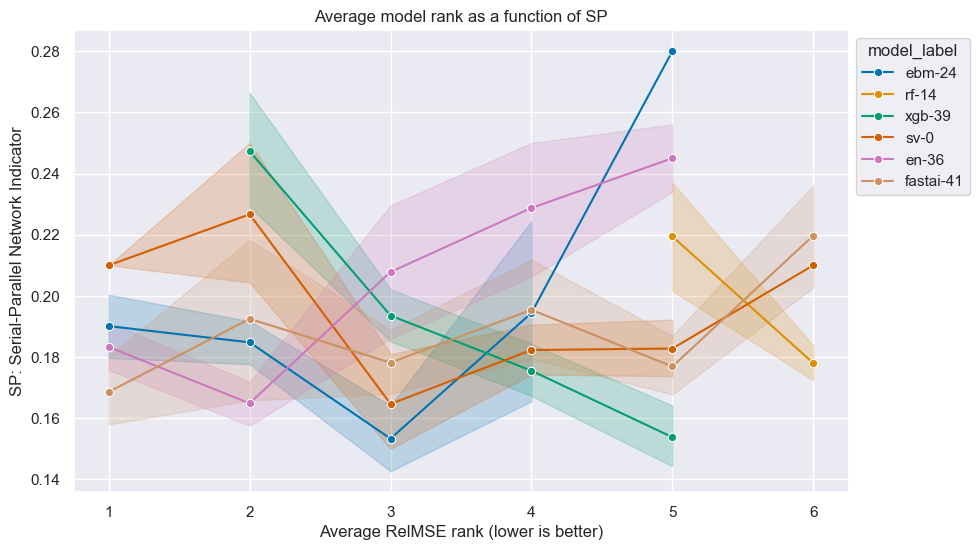

In [15]:
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=analysis_data,
    y="SP",
    x="RelMSE_rank",
    hue="model_label",
    hue_order=model_label_order,
    palette=model_palette,
    estimator="mean",
    errorbar=("ci", 95),
    marker="o",
)
sns.move_legend(plt.gca(), "upper left", bbox_to_anchor=(1, 1))
plt.title("Average model rank as a function of SP")
plt.ylabel("SP: Serial-Parallel Network Indicator")
plt.xlabel("Average RelMSE rank (lower is better)")
plt.show()

In [12]:
sp_project_bins = pd.qcut(project_topology["SP"], q=4, duplicates="drop")
project_topology_with_bins = project_topology.assign(SP_bin=sp_project_bins.astype(str))

analysis_data = analysis_data.merge(
    project_topology_with_bins[["SP_bin"]].reset_index(),
    on="project",
    how="left",
)

sp_bin_summary = (
    analysis_data
    .groupby(["SP_bin", "model_label"], observed=True)
    .agg(
        n_projects=("project", "nunique"),
        mean_RelMSE=("RelMSE", "mean"),
        median_RelMSE=("RelMSE", "median"),
        mean_RelMSE_rank=("RelMSE_rank", "mean"),
        wins=("is_best_model", "sum"),
    )
    .reset_index()
    .sort_values(["SP_bin", "mean_RelMSE_rank"])
)

sp_bin_summary

,SP_bin,model_label,n_projects,mean_RelMSE,median_RelMSE,mean_RelMSE_rank,wins
1,"(0.089, 0.14]",en-36,108,0.016279,0.003082,1.398148,67
0,"(0.089, 0.14]",ebm-24,108,0.020480,0.002894,2.120370,14
2,"(0.089, 0.14]",fastai-41,108,0.062549,0.024021,3.425926,27
5,"(0.089, 0.14]",xgb-39,108,0.039437,0.019725,3.907407,0
4,"(0.089, 0.14]",sv-0,108,0.039937,0.022422,4.185185,0
3,"(0.089, 0.14]",rf-14,108,0.239835,0.231061,5.962963,0
7,"(0.14, 0.17]",en-36,86,0.012889,0.006164,1.523256,48
6,"(0.14, 0.17]",ebm-24,86,0.014315,0.004583,1.965116,22
8,"(0.14, 0.17]",fastai-41,86,0.058519,0.022360,3.395349,16
11,"(0.14, 0.17]",xgb-39,86,0.030660,0.019078,3.848837,0


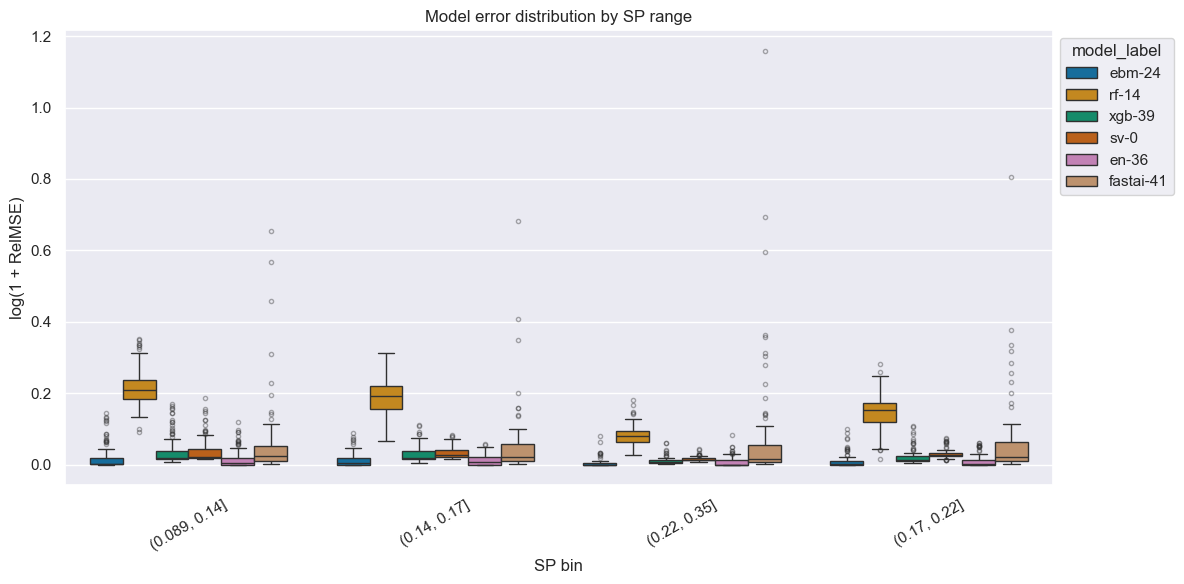

In [13]:
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=analysis_data,
    x="SP_bin",
    y="log_RelMSE",
    hue="model_label",
    hue_order=model_label_order,
    palette=model_palette,
    flierprops=dict(marker="o", markersize=3, alpha=0.4),
)
sns.move_legend(plt.gca(), "upper left", bbox_to_anchor=(1, 1))
plt.title("Model error distribution by SP range")
plt.xlabel("SP bin")
plt.ylabel("log(1 + RelMSE)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [14]:
sp_win_table = (
    analysis_data
    .loc[analysis_data["is_best_model"]]
    .groupby(["SP_bin", "model_label"], observed=True)
    .size()
    .unstack(fill_value=0)
    .reindex(columns=model_label_order, fill_value=0)
)

sp_win_share = sp_win_table.div(sp_win_table.sum(axis=1), axis=0)
display(sp_win_table)
display(sp_win_share)

model_label,ebm-24,rf-14,xgb-39,sv-0,en-36,fastai-41
SP_bin,,,,,,
"(0.089, 0.14]",14,0,0,0,67,27
"(0.14, 0.17]",22,0,0,0,48,16
"(0.17, 0.22]",22,0,0,2,50,11
"(0.22, 0.35]",20,0,0,0,50,11


model_label,ebm-24,rf-14,xgb-39,sv-0,en-36,fastai-41
SP_bin,,,,,,
"(0.089, 0.14]",0.129630,0.0,0.0,0.000000,0.620370,0.250000
"(0.14, 0.17]",0.255814,0.0,0.0,0.000000,0.558140,0.186047
"(0.17, 0.22]",0.258824,0.0,0.0,0.023529,0.588235,0.129412
"(0.22, 0.35]",0.246914,0.0,0.0,0.000000,0.617284,0.135802


## Correlation Between Topology and Performance

The next tables report Spearman correlations between each topological descriptor and model performance. Positive correlation with `RelMSE_rank` means that the model tends to rank worse as the descriptor increases; negative correlation means it tends to rank better.

In [15]:
def spearman_by_model(data: pd.DataFrame, metric: str, topology_cols: list[str]) -> pd.DataFrame:
    rows = []
    for model_label, group in data.groupby("model_label"):
        for col in topology_cols:
            clean = group[[metric, col]].dropna()
            rho, pvalue = ss.spearmanr(clean[col], clean[metric])
            rows.append({
                "model_label": model_label,
                "topology_metric": col,
                "performance_metric": metric,
                "spearman_rho": rho,
                "pvalue": pvalue,
                "n": len(clean),
            })
    return pd.DataFrame(rows)


rank_topology_corr = spearman_by_model(analysis_data, "RelMSE_rank", topology_cols)
error_topology_corr = spearman_by_model(analysis_data, "log_RelMSE", topology_cols)

rank_corr_matrix = rank_topology_corr.pivot(index="model_label", columns="topology_metric", values="spearman_rho").reindex(model_label_order)
error_corr_matrix = error_topology_corr.pivot(index="model_label", columns="topology_metric", values="spearman_rho").reindex(model_label_order)

display(rank_topology_corr.sort_values(["topology_metric", "pvalue"]).head(20))

,model_label,topology_metric,performance_metric,spearman_rho,pvalue,n
40,xgb-39,#Act,RelMSE_rank,0.384129,4.195433e-14,360
24,rf-14,#Act,RelMSE_rank,0.249541,1.632382e-06,360
0,ebm-24,#Act,RelMSE_rank,0.150080,4.319347e-03,360
16,fastai-41,#Act,RelMSE_rank,-0.145183,5.785143e-03,360
8,en-36,#Act,RelMSE_rank,-0.101733,5.378737e-02,360
32,sv-0,#Act,RelMSE_rank,-0.083327,1.145042e-01,360
12,en-36,AD,RelMSE_rank,-0.172022,1.049170e-03,360
28,rf-14,AD,RelMSE_rank,0.105074,4.634573e-02,360
36,sv-0,AD,RelMSE_rank,0.055861,2.905019e-01,360
4,ebm-24,AD,RelMSE_rank,0.050261,3.416466e-01,360


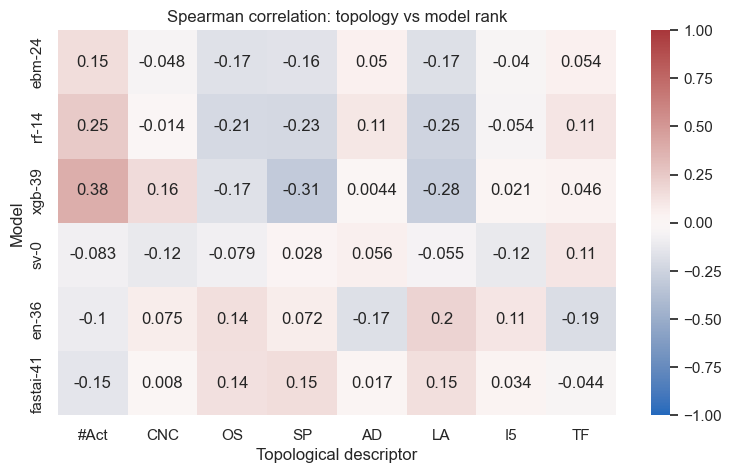

topology_metric,#Act,AD,CNC,I5,LA,OS,SP,TF
model_label,,,,,,,,
ebm-24,0.150080,0.050261,-0.047666,-0.040243,-0.173990,-0.165604,-0.161680,0.053580
rf-14,0.249541,0.105074,-0.013920,-0.053903,-0.248083,-0.212364,-0.226440,0.112876
xgb-39,0.384129,0.004430,0.159586,0.021166,-0.276622,-0.166970,-0.308435,0.046271
sv-0,-0.083327,0.055861,-0.123038,-0.120116,-0.055141,-0.079363,0.028234,0.114040
en-36,-0.101733,-0.172022,0.074614,0.113173,0.196810,0.141654,0.071714,-0.192487
fastai-41,-0.145183,0.016878,0.007985,0.033822,0.146206,0.137572,0.149453,-0.043508


In [16]:
plt.figure(figsize=(9, 5))
sns.heatmap(rank_corr_matrix[topology_cols], annot=True, cmap="vlag", center=0, vmin=-1, vmax=1)
plt.title("Spearman correlation: topology vs model rank")
plt.xlabel("Topological descriptor")
plt.ylabel("Model")
plt.show()

rank_corr_matrix

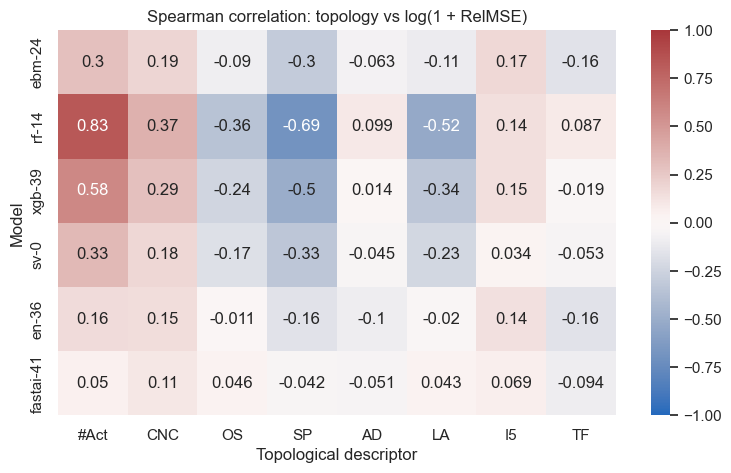

topology_metric,#Act,AD,CNC,I5,LA,OS,SP,TF
model_label,,,,,,,,
ebm-24,0.296404,-0.063434,0.191002,0.174038,-0.105062,-0.090419,-0.297075,-0.159923
rf-14,0.833245,0.099383,0.368381,0.140900,-0.523906,-0.358489,-0.689843,0.087215
xgb-39,0.582312,0.014424,0.289436,0.147190,-0.335251,-0.236165,-0.503032,-0.019459
sv-0,0.332887,-0.045234,0.181607,0.033877,-0.232344,-0.174204,-0.331134,-0.052641
en-36,0.159415,-0.099628,0.150594,0.140517,-0.020191,-0.010928,-0.162118,-0.158195
fastai-41,0.050014,-0.050612,0.109308,0.069462,0.043334,0.045584,-0.042027,-0.094379


In [17]:
plt.figure(figsize=(9, 5))
sns.heatmap(error_corr_matrix[topology_cols], annot=True, cmap="vlag", center=0, vmin=-1, vmax=1)
plt.title("Spearman correlation: topology vs log(1 + RelMSE)")
plt.xlabel("Topological descriptor")
plt.ylabel("Model")
plt.show()

error_corr_matrix

## Subset-Specific SP Relationships

Because `J30`, `J60`, `J90`, and `J120` differ structurally by number of activities, the SP-performance relationship is also inspected within each subset.

In [18]:
subset_sp_summary = (
    analysis_data
    .groupby(["subset", "model_label"], observed=True)
    .apply(
        lambda group: pd.Series({
            "n_projects": group["project"].nunique(),
            "mean_SP": group[["project", "SP"]].drop_duplicates()["SP"].mean(),
            "rho_SP_rank": ss.spearmanr(group["SP"], group["RelMSE_rank"]).statistic,
            "pvalue_SP_rank": ss.spearmanr(group["SP"], group["RelMSE_rank"]).pvalue,
            "mean_RelMSE_rank": group["RelMSE_rank"].mean(),
            "wins": group["is_best_model"].sum(),
        })
    )
    .reset_index()
    .sort_values(["subset", "mean_RelMSE_rank"])
)

subset_sp_summary

C:\Users\nacho\AppData\Local\Temp\ipykernel_29624\2833555720.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


,subset,model_label,n_projects,mean_SP,rho_SP_rank,pvalue_SP_rank,mean_RelMSE_rank,wins
1,J120,en-36,90.0,0.126444,0.184371,0.081930,1.400000,56.0
0,J120,ebm-24,90.0,0.126444,-0.050549,0.636110,2.122222,12.0
2,J120,fastai-41,90.0,0.126444,-0.025584,0.810831,3.422222,22.0
5,J120,xgb-39,90.0,0.126444,0.344325,0.000890,4.011111,0.0
4,J120,sv-0,90.0,0.126444,-0.465876,0.000004,4.066667,0.0
3,J120,rf-14,90.0,0.126444,0.065448,0.539960,5.977778,0.0
6,J30,ebm-24,90.0,0.256667,-0.052793,0.621181,1.922222,22.0
7,J30,en-36,90.0,0.256667,-0.276886,0.008244,2.033333,52.0
11,J30,xgb-39,90.0,0.256667,0.093945,0.378465,3.200000,0.0
8,J30,fastai-41,90.0,0.256667,0.113938,0.284940,3.977778,14.0


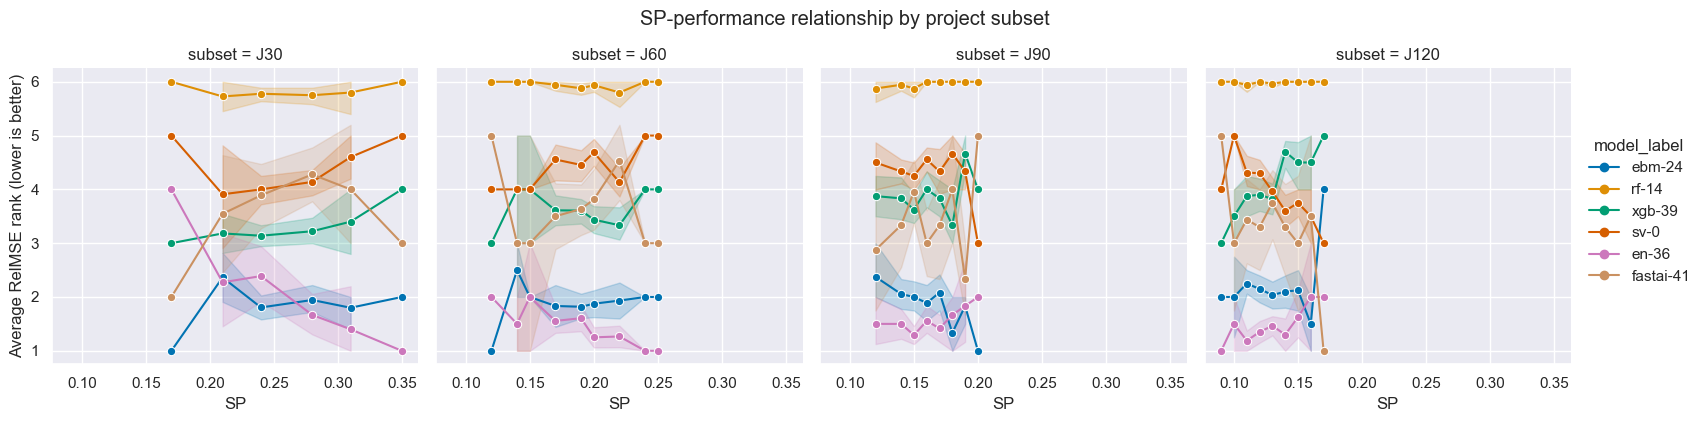

In [19]:
g = sns.relplot(
    data=analysis_data,
    x="SP",
    y="RelMSE_rank",
    hue="model_label",
    hue_order=model_label_order,
    palette=model_palette,
    col="subset",
    col_order=["J30", "J60", "J90", "J120"],
    kind="line",
    estimator="mean",
    errorbar=("ci", 95),
    marker="o",
    height=4,
    aspect=1,
)
g.set_axis_labels("SP", "Average RelMSE rank (lower is better)")
g.fig.suptitle("SP-performance relationship by project subset", y=1.05)
plt.show()

## Best Model Regions

This section describes where each model wins in terms of the topology space. It is descriptive: it does not imply causal effects, but it helps identify the project structures where a model tends to be competitive.

In [20]:
best_model_topology_summary = (
    analysis_data
    .loc[analysis_data["is_best_model"]]
    .groupby("model_label")
    .agg(
        wins=("project", "nunique"),
        median_SP=("SP", "median"),
        mean_SP=("SP", "mean"),
        median_CNC=("CNC", "median"),
        median_OS=("OS", "median"),
        median_TF=("TF", "median"),
        median_Act=("#Act", "median"),
    )
    .reindex(model_label_order)
    .fillna({"wins": 0})
)

best_model_topology_summary

,wins,median_SP,mean_SP,median_CNC,median_OS,median_TF,median_Act
model_label,,,,,,,
ebm-24,78.0,0.19,0.190128,1.78,0.385,0.220,60.0
rf-14,0.0,NaN,NaN,NaN,NaN,NaN,NaN
xgb-39,0.0,NaN,NaN,NaN,NaN,NaN,NaN
sv-0,2.0,0.21,0.210000,1.90,0.475,0.035,30.0
en-36,215.0,0.17,0.183302,1.77,0.330,0.240,90.0
fastai-41,65.0,0.15,0.168615,1.78,0.320,0.220,90.0


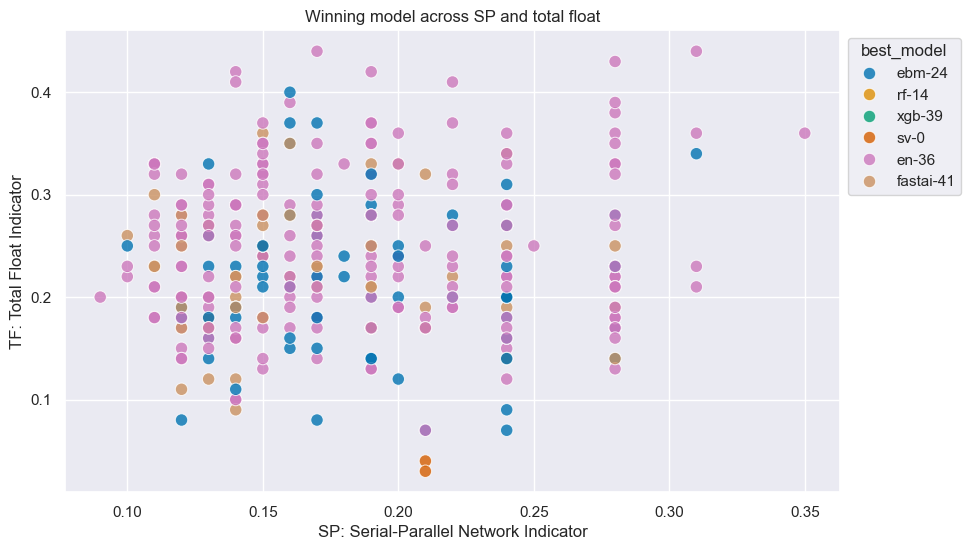

In [21]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=project_topology.join(best_model),
    x="SP",
    y="TF",
    hue="best_model",
    hue_order=model_label_order,
    palette=model_palette,
    #style="metadata_subset",
    s=80,
    alpha=0.8,
)
sns.move_legend(plt.gca(), "upper left", bbox_to_anchor=(1, 1))
plt.title("Winning model across SP and total float")
plt.xlabel("SP: Serial-Parallel Network Indicator")
plt.ylabel("TF: Total Float Indicator")
plt.show()

## SP-TF Dominance Grid

The scatter plot above shows individual projects. The grid below aggregates the same information into SP-TF cells and colors each cell with the model that wins most often inside it. Empty cells are left blank, and cells with no unique winner are marked as ties.

In [22]:
def build_dominance_grid(
    project_topology: pd.DataFrame,
    best_model: pd.Series,
    model_label_order: list[str],
    x_col: str = "SP",
    y_col: str = "TF",
    n_x_bins: int = 6,
    n_y_bins: int = 6,
) -> tuple[pd.DataFrame, np.ndarray, np.ndarray]:
    """Bin the topology space and identify the most frequent winning model per cell."""

    grid_data = project_topology[[x_col, y_col]].join(best_model).dropna()

    x_edges = np.linspace(grid_data[x_col].min(), grid_data[x_col].max(), n_x_bins + 1)
    y_edges = np.linspace(grid_data[y_col].min(), grid_data[y_col].max(), n_y_bins + 1)

    grid_data = grid_data.assign(
        x_bin=pd.cut(grid_data[x_col], x_edges, labels=False, include_lowest=True),
        y_bin=pd.cut(grid_data[y_col], y_edges, labels=False, include_lowest=True),
    )

    rows = []
    for y_bin in range(n_y_bins):
        for x_bin in range(n_x_bins):
            cell = grid_data.query("x_bin == @x_bin and y_bin == @y_bin")
            counts = cell["best_model"].value_counts().reindex(model_label_order, fill_value=0)

            n_projects = int(counts.sum())
            max_wins = counts.max()
            winners = counts[counts == max_wins].index.tolist()

            is_empty = n_projects == 0
            is_tie = len(winners) > 1 and not is_empty

            rows.append({
                f"{x_col}_bin": x_bin,
                f"{y_col}_bin": y_bin,
                f"{x_col}_min": x_edges[x_bin],
                f"{x_col}_max": x_edges[x_bin + 1],
                f"{y_col}_min": y_edges[y_bin],
                f"{y_col}_max": y_edges[y_bin + 1],
                "n_projects": n_projects,
                "dominant_model": np.nan if is_empty else ("tie" if is_tie else winners[0]),
                "dominant_wins": 0 if is_empty else int(max_wins),
                "is_tie": is_tie,
                **{f"wins_{model}": int(counts[model]) for model in model_label_order},
            })

    return pd.DataFrame(rows), x_edges, y_edges

## SP-TF Quartile Statistical Dominance Grid

The previous 6 x 6 grid is descriptive and may contain cells with too few projects for inference. This second grid uses `SP` quartiles crossed with `TF` quartiles. For each cell, the model with the best average rank is shown as `best`.

The cell color represents the statistical conclusion, not only the descriptive winner. A single-model color means that model is statistically dominant. A group color such as `en-36 + ebm-24` means the first model is best by average rank, but Conover does not find a significant difference between the models in that group. Gray cells indicate non-conclusive cases: insufficient sample size or no significant Friedman result.

In [23]:
def format_interval(interval, decimals=2):
    """Format a pandas interval for display."""

    return (
        f"{'[' if interval.closed_left else '('}"
        f"{interval.left:.{decimals}f}, "
        f"{interval.right:.{decimals}f}"
        f"{']' if interval.closed_right else ')'}"
    )


def build_quartile_statistical_dominance_grid(
    project_topology: pd.DataFrame,
    relmse_matrix: pd.DataFrame,
    model_label_order: list[str],
    x_col: str = "SP",
    y_col: str = "TF",
    min_projects: int = 15,
    significance: float = 0.05,
    p_adjust: str = "bonferroni",
) -> pd.DataFrame:
    """Build a quartile topology grid and test model differences within each cell."""

    topology_bins = project_topology[[x_col, y_col]].assign(
        x_quartile=lambda df: pd.qcut(df[x_col], q=4, duplicates="drop"),
        y_quartile=lambda df: pd.qcut(df[y_col], q=4, duplicates="drop"),
    )

    rows = []

    for y_idx, y_bin in enumerate(topology_bins["y_quartile"].cat.categories):
        for x_idx, x_bin in enumerate(topology_bins["x_quartile"].cat.categories):

            projects = topology_bins.index[
                topology_bins["x_quartile"].eq(x_bin)
                & topology_bins["y_quartile"].eq(y_bin)
            ]

            cell_data = relmse_matrix.loc[projects, model_label_order].dropna()
            n_projects = len(cell_data)

            row = {
                f"{x_col}_quartile": format_interval(x_bin),
                f"{y_col}_quartile": format_interval(y_bin),
                f"{x_col}_bin": x_idx,
                f"{y_col}_bin": y_idx,
                "n_projects": n_projects,
                "dominant_model": np.nan,
                "mean_rank_best": np.nan,
                "friedman_statistic": np.nan,
                "friedman_pvalue": np.nan,
                "test_status": "empty",
                "conover_group": "",
            }

            if n_projects == 0:
                rows.append(row)
                continue

            ranks = cell_data.rank(axis=1, ascending=True, method="average")
            avg_rank = ranks.mean().sort_values()
            dominant_model = avg_rank.index[0]

            row.update({
                "dominant_model": dominant_model,
                "mean_rank_best": avg_rank.loc[dominant_model],
                "test_status": "insufficient_n" if n_projects < min_projects else "tested",
                "conover_group": dominant_model,
                **{f"mean_rank_{model}": avg_rank.get(model, np.nan) for model in model_label_order},
            })

            if n_projects >= min_projects:
                friedman = ss.friedmanchisquare(
                    *[cell_data[col].to_numpy() for col in cell_data.columns]
                )

                row["friedman_statistic"] = friedman.statistic
                row["friedman_pvalue"] = friedman.pvalue

                if friedman.pvalue < significance:
                    conover = sp.posthoc_conover_friedman(cell_data, p_adjust=p_adjust)
                    conover = conover.loc[avg_rank.index, avg_rank.index]

                    conover_group = (
                        conover.loc[dominant_model]
                        .loc[lambda p: p >= significance]
                        .index
                    )
                    conover_group = avg_rank.loc[conover_group].sort_values().index.tolist()

                    row["test_status"] = "friedman_significant"
                    row["conover_group"] = ", ".join(conover_group)

                else:
                    row["test_status"] = "friedman_not_significant"
                    row["conover_group"] = ", ".join(avg_rank.index)

            rows.append(row)

    return pd.DataFrame(rows)

def normalize_statistical_group(group: str, model_label_order: list[str]) -> str:
    """Normalize a Conover group so equivalent sets share label and color."""

    if not group:
        return "empty"

    members = {member.strip() for member in group.split(",") if member.strip()}
    ordered_members = [model for model in model_label_order if model in members]

    return (
        "all models"
        if len(ordered_members) == len(model_label_order)
        else " + ".join(ordered_members)
    )

def add_statistical_group_labels(
    quartile_grid: pd.DataFrame,
    model_label_order: list[str],
) -> pd.DataFrame:
    """Add the categorical statistical conclusion used for plotting."""

    def label_row(row):
        if row["test_status"] == "empty":
            return "empty"
        if row["test_status"] == "insufficient_n":
            return "insufficient n"
        if row["test_status"] == "friedman_not_significant":
            return "all models"
        return normalize_statistical_group(row["conover_group"], model_label_order)

    grid = quartile_grid.copy()
    grid["statistical_group"] = grid.apply(label_row, axis=1)

    return grid

def plot_quartile_statistical_dominance_grid(
    quartile_grid: pd.DataFrame,
    model_label_order: list[str],
    x_col: str = "SP",
    y_col: str = "TF",
    title: str = "SP-TF quartile statistical dominance grid",
) -> pd.DataFrame:
    """Plot statistical dominance groups across topology quartiles."""

    grid = add_statistical_group_labels(quartile_grid, model_label_order)

    special_labels = ["empty", "insufficient n", "all models"]

    group_labels = [
        label
        for label in grid["statistical_group"].dropna().unique()
        if label not in special_labels and label not in model_label_order
    ]

    group_colors = sns.color_palette("colorblind", n_colors=max(1, len(group_labels)))

    palette = {
        **model_palette,
        **dict(zip(group_labels, group_colors)),
        "insufficient n": (0.82, 0.82, 0.82),
        "all models": (0.92, 0.92, 0.92),
        "empty": "white",
    }

    hatches = {
        "friedman_not_significant": "..",
    }

    fig, ax = plt.subplots(figsize=(12, 8))

    for row in grid.itertuples():
        x = getattr(row, f"{x_col}_bin")
        y = getattr(row, f"{y_col}_bin")

        n_projects = int(row.n_projects)
        dominant_model = row.dominant_model
        statistical_group = row.statistical_group

        if n_projects == 0 or pd.isna(dominant_model):
            facecolor = palette["empty"]
            label = ""
        else:
            facecolor = palette[statistical_group]
            label = (
                f"best: {dominant_model}\n"
                f"n={n_projects}\n"
                f"group: {statistical_group}"
            )

        ax.add_patch(
            plt.Rectangle(
                (x, y),
                1,
                1,
                facecolor=facecolor,
                edgecolor="black",
                linewidth=1.5 if statistical_group == "insufficient n" else 0.9,
                alpha=0.82,
                hatch=hatches.get(row.test_status, ""),
            )
        )

        if label:
            ax.text(
                x + 0.5,
                y + 0.5,
                label,
                ha="center",
                va="center",
                fontsize=9.5,
                wrap=True,
                bbox=dict(
                    facecolor="white",
                    alpha=0.68,
                    edgecolor="none",
                    boxstyle="round,pad=0.2",
                ),
            )

    x_labels = (
        grid.sort_values(f"{x_col}_bin")
        .drop_duplicates(f"{x_col}_bin")
        [f"{x_col}_quartile"]
        .tolist()
    )

    y_labels = (
        grid.sort_values(f"{y_col}_bin")
        .drop_duplicates(f"{y_col}_bin")
        [f"{y_col}_quartile"]
        .tolist()
    )

    ax.set_xlim(0, len(x_labels))
    ax.set_ylim(0, len(y_labels))
    ax.set_xticks(np.arange(len(x_labels)) + 0.5)
    ax.set_yticks(np.arange(len(y_labels)) + 0.5)
    ax.set_xticklabels(x_labels, rotation=20, ha="right")
    ax.set_yticklabels(y_labels)
    ax.set_xlabel(f"{x_col} quartile")
    ax.set_ylabel(f"{y_col} quartile")
    ax.set_title(title)

    legend_labels = [
        label
        for label in grid["statistical_group"].dropna().unique()
        if label != "empty"
    ]

    handles = [
        plt.Line2D(
            [0], [0],
            marker="s",
            linestyle="",
            color=palette[label],
            label=label,
            markersize=10,
        )
        for label in sorted(legend_labels)
    ]

    ax.legend(
        handles=handles,
        title="Statistical group",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
    )

    plt.tight_layout()
    plt.show()

    return grid

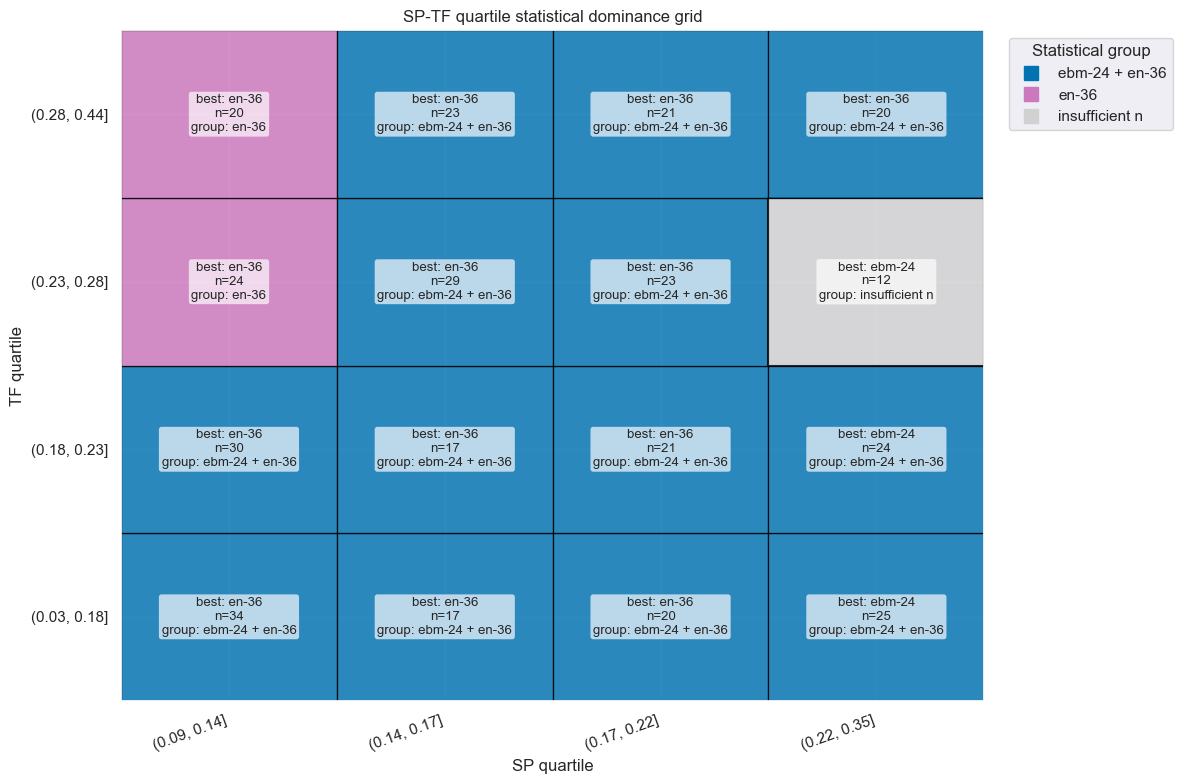

,SP_quartile,TF_quartile,SP_bin,TF_bin,n_projects,dominant_model,mean_rank_best,friedman_statistic,friedman_pvalue,test_status,conover_group,mean_rank_ebm-24,mean_rank_rf-14,mean_rank_xgb-39,mean_rank_sv-0,mean_rank_en-36,mean_rank_fastai-41,statistical_group
0,"(0.09, 0.14]","(0.03, 0.18]",0,0,34,en-36,1.529412,120.470588,2.494904e-24,friedman_significant,"en-36, ebm-24",2.058824,5.941176,3.911765,4.058824,1.529412,3.500000,ebm-24 + en-36
1,"(0.14, 0.17]","(0.03, 0.18]",1,0,17,en-36,1.588235,67.084034,4.139117e-13,friedman_significant,"en-36, ebm-24",1.705882,5.941176,3.470588,4.411765,1.588235,3.882353,ebm-24 + en-36
2,"(0.17, 0.22]","(0.03, 0.18]",2,0,20,en-36,1.750000,66.857143,4.613540e-13,friedman_significant,"en-36, ebm-24",1.850000,5.800000,3.500000,4.150000,1.750000,3.950000,ebm-24 + en-36
3,"(0.22, 0.35]","(0.03, 0.18]",3,0,25,ebm-24,1.840000,73.251429,2.154564e-14,friedman_significant,"ebm-24, en-36",1.840000,5.680000,3.200000,3.880000,2.120000,4.280000,ebm-24 + en-36
4,"(0.09, 0.14]","(0.18, 0.23]",0,1,30,en-36,1.500000,106.723810,2.016414e-21,friedman_significant,"en-36, ebm-24",2.233333,5.966667,4.000000,4.133333,1.500000,3.166667,ebm-24 + en-36
5,"(0.14, 0.17]","(0.18, 0.23]",1,1,17,en-36,1.529412,67.588235,3.252048e-13,friedman_significant,"en-36, ebm-24",2.000000,5.941176,3.941176,4.647059,1.529412,2.941176,ebm-24 + en-36
6,"(0.17, 0.22]","(0.18, 0.23]",2,1,21,en-36,1.619048,72.782313,2.698697e-14,friedman_significant,"en-36, ebm-24",1.952381,5.857143,3.476190,4.190476,1.619048,3.904762,ebm-24 + en-36
7,"(0.22, 0.35]","(0.18, 0.23]",3,1,24,ebm-24,1.875000,70.785714,7.032137e-14,friedman_significant,"ebm-24, en-36",1.875000,5.750000,3.250000,4.083333,2.083333,3.958333,ebm-24 + en-36
8,"(0.09, 0.14]","(0.23, 0.28]",0,2,24,en-36,1.333333,93.857143,1.038739e-18,friedman_significant,en-36,2.166667,5.958333,3.708333,4.541667,1.333333,3.291667,en-36
9,"(0.14, 0.17]","(0.23, 0.28]",1,2,29,en-36,1.620690,104.527094,5.865378e-21,friedman_significant,"en-36, ebm-24",2.172414,6.000000,4.034483,4.206897,1.620690,2.965517,ebm-24 + en-36


In [24]:
quartile_statistical_grid = build_quartile_statistical_dominance_grid(
    project_topology=project_topology,
    relmse_matrix=relmse_matrix,
    model_label_order=model_label_order,
    x_col="SP",
    y_col="TF",
    min_projects=15,
)

quartile_statistical_grid = plot_quartile_statistical_dominance_grid(
    quartile_statistical_grid,
    model_label_order,
    x_col="SP",
    y_col="TF",
)

quartile_statistical_grid.sort_values(["TF_bin", "SP_bin"])

## Save Analysis Tables

In [27]:
outputs = {
    "topology_rank_spearman_by_model.csv": rank_topology_corr,
    "topology_error_spearman_by_model.csv": error_topology_corr,
    "topology_sp_bin_model_summary.csv": sp_bin_summary,
    "topology_sp_bin_wins.csv": sp_win_table,
    "topology_sp_bin_win_share.csv": sp_win_share,
    "topology_subset_sp_summary.csv": subset_sp_summary,
    "topology_best_model_regions.csv": best_model_topology_summary,
    "topology_sp_tf_quartile_statistical_grid.csv": quartile_statistical_grid,
    "topology_model_performance_long.csv": analysis_data,
}

for filename, df in outputs.items():
    df.to_csv(work_dir / filename, index=False)